# Step 33: Which features matter (review E11)
TreeSHAP of an XGBoost model trained on the 797 voice + face features, explained on unseen people (up to 600 windows per language and fold). Importance = mean |SHAP|. The data has no feature names, so single features are shown by position (voice_k = k-th eGeMAPS value, face_k = k-th OpenFace column).
*This notebook only loads the saved results of `src/33_shap_features.py`; it does not train anything and needs no NoXi data.*

**In short** (what this notebook shows)

- **What:** Which features matter (review E11): TreeSHAP of XGBoost, by feature group and by language.
- **Needs the NoXi data?** No: it loads reports/shap_*.csv (made by src/33_shap_features.py).
- **Result / use:** The 88 voice features carry 43% of the importance, about 6 times more per feature than the face; the three languages agree.

Go to the project folder.

In [2]:
import os
if os.getcwd().endswith("notebooks"):
    os.chdir("..")          # work from the project folder

**Imports.**

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
pd.set_option('display.width', 220)

**By feature group** (% of total importance, overall and by language).

In [4]:
sg = pd.read_csv('reports/shap_groups.csv')
print(sg.round(1).to_string(index=False))

                                         group  n_features  share_all  share_English  share_French  share_German
face: other OpenFace values (landmarks, shape)         660       44.7           42.7          44.0          46.7
                               voice (eGeMAPS)          88       42.8           44.5          43.1          41.3
                   face: action-unit intensity          17        6.1            6.0           6.4           5.9
                    face: action-unit presence          18        3.6            3.6           3.8           3.5
                                    face: gaze           8        2.0            2.4           2.0           1.9
                               face: head pose           6        0.7            0.8           0.7           0.7


**Top 15 single features.**

In [5]:
sf = pd.read_csv('reports/shap_features.csv')
print(sf.head(15)[['rank', 'feature', 'group', 'share_pct', 'mean_abs_shap_English', 'mean_abs_shap_French', 'mean_abs_shap_German', 'direction']].round(4).to_string(index=False))

 rank  feature                                          group  share_pct  mean_abs_shap_English  mean_abs_shap_French  mean_abs_shap_German                         direction
    1 voice_44                                voice (eGeMAPS)     4.1783                 0.0170                0.0140                0.0136 higher value -> higher engagement
    2 voice_16                                voice (eGeMAPS)     2.8855                 0.0094                0.0108                0.0097 higher value -> higher engagement
    3 voice_13                                voice (eGeMAPS)     2.7812                 0.0120                0.0093                0.0087 higher value -> higher engagement
    4  voice_7                                voice (eGeMAPS)     2.6850                 0.0103                0.0092                0.0090 higher value -> higher engagement
    5 voice_67                                voice (eGeMAPS)     2.2438                 0.0081                0.0075             

**Do the languages agree?** Rank correlation over all 797 features and overlap of the top 20.

In [6]:
print(pd.read_csv('reports/shap_language_agreement.csv').round(3).to_string(index=False))

language_a language_b  spearman_all_797  top20_overlap
   English     French             0.888             14
   English     German             0.896             16
    French     German             0.945             16


**Chart** (saved by the script).

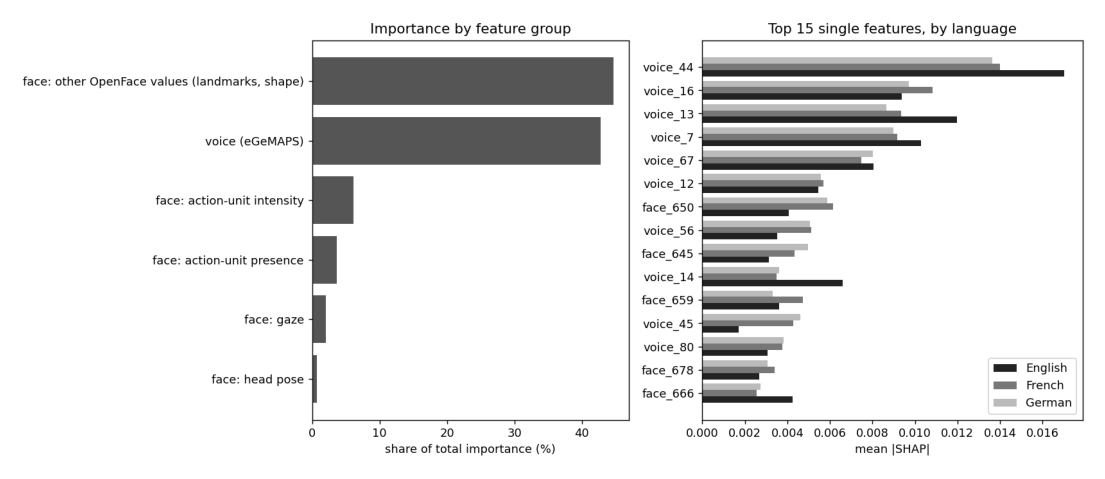

In [7]:
plt.figure(figsize=(14, 6)); plt.imshow(mpimg.imread('charts/shap_features.png')); plt.axis('off'); plt.show()

**Reading.** The 88 voice features carry about 43% of the importance, roughly 6 times more per feature than the 709 face features; 14 of the top 20 features are voice features and the three languages rank the features alike. Importance is not accuracy: many correlated face features can share a large part of the total.